# Praktikum Data Mining – Evaluasi Model Klasifikasi
## 4.1 – Menyiapkan Dataset Sintetis
Kelompok 7 Data Mining

Anggota: Lutfiah Sahira (24343039), Imam Atthahira (24343037) , Rangga Dharma Putra (24343045). Mata kuliah: Data Mining· Dosen pengampu: Dr. Yeka Hendriyani, S.Kom., M.Kom. Program Studi Informatika, Departemen Teknik Elektronika, Fakultas Teknik, Universitas Negeri Padang

### Langkah 4.1

In [1]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)
score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)
df = pd.DataFrame({'amount':amount.round(2), 'hour':hour,
                   'new_device':new_device, 'foreign_ip':foreign_ip,
                   'isFraud':isFraud})
pd.set_option('display.width', 120)
print(df.head())
print('Distribusi kelas:')
print(df['isFraud'].value_counts())
print('Proporsi fraud:', round(df['isFraud'].mean()*100, 2), '%')

   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0
Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64
Proporsi fraud: 3.2 %


### Sel 4.1b

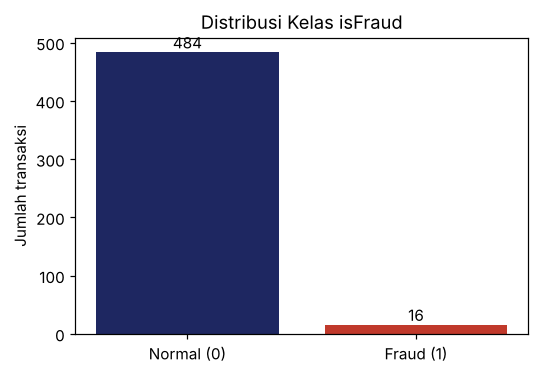

In [2]:
import matplotlib.pyplot as plt
counts = df['isFraud'].value_counts().sort_index()
plt.figure(figsize=(5, 3.5))
bars = plt.bar(['Normal (0)', 'Fraud (1)'], counts.values, color=['#1E2761', '#C0392B'])
plt.bar_label(bars)
plt.ylabel('Jumlah transaksi')
plt.title('Distribusi Kelas isFraud')
plt.tight_layout()
plt.show()